# 03b: Qdlin tail sanity and window regrid
Patch phase for the battery SOH project. Diagnoses the Qdlin tail problem, builds mask v2 and a causal per-window validity function, and redoes the window audit on a finer grid. No models (only 1- and 2-variable linear canaries), no scaling, no changes to splits or labels. Raw .mat files are not touched.

## 1. Setup and guards

In [1]:
import json, time, hashlib, ast, sys, os, importlib, warnings
from pathlib import Path
import numpy as np, pandas as pd, psutil
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.base import BaseEstimator
from tqdm import tqdm

T0 = time.time()
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
PROC = ROOT/"data/processed"; SPL = PROC/"splits"; P3 = ROOT/"outputs/phase3"
OUT = ROOT/"outputs/phase3b"; FIG = OUT/"figures"; SRC = ROOT/"src"
OUT.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)

SEED = 42; NOMINAL_AH = 1.1; CANARY_R2 = 0.98; LATE_WINDOW_L = 0.60
TAIL_LO = 0.80; TAIL_HI = 1.02; MAX_STEP_AH = 0.05
np.random.seed(SEED); rng = np.random.default_rng(SEED)
VSTEP = 0.0015015; NGRID = 1000; MIN_PER_AH = 15.0
QS = [0, 0.1, 1, 5, 50, 95, 99, 99.9, 100]
VGRID = 3.5 - np.arange(NGRID)*VSTEP
def vidx(v):
    return int(round((3.5 - v)/VSTEP))

CHECKS = []; ERRORS = []; REP = {}
def check(name, passed, detail=""):
    status = "WARN" if passed == "WARN" else ("PASS" if passed else "FAIL")
    CHECKS.append({"name": name, "status": status, "detail": str(detail)})
    print(f"[{status}] {name}: {detail}")
def expect(name, ok, detail=""):
    check(name, True if ok else "WARN", detail)
def record_error(where, exc):
    ERRORS.append(f"{where}: {type(exc).__name__}: {exc}"); print("ERROR", ERRORS[-1])

def guard_write(p):
    p = Path(p).resolve()
    assert SPL.resolve() not in [p, *p.parents], f"refusing to write inside splits: {p}"
    allowed = [OUT.resolve(), (PROC/"labels_table_v2.parquet").resolve(), (SRC/"soh_common.py").resolve()]
    assert any(p == a or a in p.parents for a in allowed), f"write outside allowed set: {p}"
    return p

def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for blk in iter(lambda: f.read(1 << 20), b""):
            h.update(blk)
    return h.hexdigest()
print("ROOT:", ROOT)

ROOT: c:\workstation\3RD YEAR\Battery-Health-Estimation


In [2]:
vm = psutil.virtual_memory()
expect("RAM available >= 2 GB", vm.available >= 2e9, f"{vm.available/1e9:.1f} GB free of {vm.total/1e9:.1f} GB")

cyc = pd.read_parquet(PROC/"cycles_table.parquet")
lab = pd.read_parquet(PROC/"labels_table.parquet")
print("cycles_table schema:"); print(cyc.dtypes.to_string())
print("labels_table schema:"); print(lab.dtypes.to_string())
NEED = ["row_id", "cell_id", "batch", "cycle_number", "soh_nom", "soh_rel", "soh_nom_repaired", "in_life",
        "qdlin_ok", "causal_ok", "label_suspect", "post_junction", "scored", "scored_incl_suspect", "train_ok"]
miss = [c for c in NEED if c not in lab.columns]
check("labels_table has the expected columns", not miss, miss)
assert not miss
ref = pd.read_csv(PROC/"cell_reference.csv")
print("cell_reference columns:", list(ref.columns))
Q = np.load(PROC/"qdlin_f32.npy", mmap_mode="r")
TK = np.load(PROC/"t_knots_f32.npy")
QREF = np.load(PROC/"qref_f32.npy", mmap_mode="r")
N = len(cyc)
expect("cycles_table has 104,971 rows", N == 104971, N)
check("array shapes match cycles_table", Q.shape == (N, NGRID) and TK.shape == (N, 16), f"Q {Q.shape}, t_knots {TK.shape}, qref {QREF.shape}")
if "row_id" in cyc.columns:
    expect("cycles_table.row_id equals position", bool((cyc["row_id"].to_numpy() == np.arange(N)).all()))

ridx = lab["row_id"].to_numpy(int)
assert ridx.min() >= 0 and ridx.max() < N and len(np.unique(ridx)) == len(ridx)
expect("labels_table covers every array row", len(lab) == N, f"{len(lab)} labelled rows vs {N}")
cycf = cyc.iloc[ridx].reset_index(drop=True)
for c in ("cell_id", "cycle_number"):
    if c in cycf.columns:
        expect(f"cycles_table.{c} agrees with labels_table", bool((cycf[c].astype(str).to_numpy() == lab[c].astype(str).to_numpy()).all()))

# boolean views (labels_table itself is never modified)
F = {c: lab[c].fillna(False).to_numpy(bool) for c in ["in_life", "qdlin_ok", "causal_ok", "label_suspect", "post_junction",
                                                       "scored", "scored_incl_suspect", "train_ok"]}
def flag(name):
    if name in cycf.columns:
        return cycf[name].fillna(False).to_numpy(bool)
    check(f"cycles_table has {name}", "WARN", "missing, treated as all False")
    return np.zeros(len(lab), bool)
FL = {k: flag(k) for k in ["flag_qdlin_bad", "flag_qd_mismatch", "flag_diag_suspect"]}

batch = lab["batch"].to_numpy()
cell_s = lab["cell_id"].astype(str).to_numpy()
cycn = lab["cycle_number"].to_numpy()
qd = cycf["qd_sum"].to_numpy(float)   # qd_sum lives in cycles_table
F["is_dev"] = np.isin(batch, [1, 2])   # labels_table has no is_dev; development = batches 1 and 2 (batch 3 locked); cross-checked against protocol_D below
print("dev rows:", int(F["is_dev"].sum()), "| dev cells:", len(np.unique(cell_s[F["is_dev"]])))
soh = lab["soh_nom"].to_numpy(float)
CELLS_U, ccode = np.unique(cell_s, return_inverse=True)
cellbatch = np.array([batch[ccode == k][0] for k in range(len(CELLS_U))])
PP = 100.0 if np.nanmax(soh) <= 2 else 1.0
print("soh_nom range:", np.nanmin(soh), np.nanmax(soh), "-> pp factor", PP)

sc_dev = F["scored"] & F["is_dev"]
expect("scored rows = 100,795", F["scored"].sum() == 100795, int(F["scored"].sum()))
expect("scored development rows = 55,965", sc_dev.sum() == 55965, int(sc_dev.sum()))
expect("development cells with scored rows = 84", len(np.unique(ccode[sc_dev])) == 84, len(np.unique(ccode[sc_dev])))
print("in_life & ~qdlin_ok rows:", int((F["in_life"] & ~F["qdlin_ok"]).sum()), "(Phase 3 reported 294 candidate rows removed)")

# q0 per row from cell_reference.csv
idcol = "cell_id" if "cell_id" in ref.columns else ref.columns[0]
q0c = [c for c in ref.columns if c.lower().startswith("q0")] or [c for c in ref.columns if "q0" in c.lower()]
if q0c:
    q0map = dict(zip(ref[idcol].astype(str), ref[q0c[0]].astype(float)))
    q0 = pd.Series(cell_s).map(q0map).to_numpy(float)
    check("q0 column found in cell_reference.csv", True, f"{q0c[0]}; rows with q0: {int(np.isfinite(q0).sum())}")
else:
    q0 = lab["q0"].to_numpy(float)
    check("q0 source", "WARN", "no q0 column in cell_reference.csv; using labels_table.q0")

# hashes of splits and locked list versus phase 3
AH = json.loads((P3/"artifact_hashes.json").read_text(encoding="utf-8"))
HASH_VALS = set()
def _walk(o):
    if isinstance(o, dict):
        for v in o.values(): _walk(v)
    elif isinstance(o, (list, tuple)):
        for v in o: _walk(v)
    elif isinstance(o, str):
        s = o.strip().lower(); HASH_VALS.add(s); HASH_VALS.add(s.split(":")[-1])
_walk(AH)
def hash_targets():
    cand = [p for p in SPL.rglob("*") if p.is_file()]
    for d in (SPL, P3, PROC):
        cand += [p for p in d.glob("*lock*") if p.is_file()]
    return sorted(set(cand))
def verify_hashes():
    return [(str(p.relative_to(ROOT)), sha256(p) in HASH_VALS) for p in hash_targets()]
H0 = verify_hashes()
bad_h = [n for n, ok in H0 if not ok]
check("split files and locked list match phase3 artifact_hashes.json", len(H0) > 0 and not bad_h, f"{len(H0)} files, mismatching or unlisted: {bad_h[:10]}")
assert len(H0) > 0 and not bad_h, "split or locked-list hash mismatch"

# snapshots for end-of-notebook integrity checks
LABELS_SHA0 = sha256(PROC/"labels_table.parquet")
SC = SRC/"soh_common.py"
SC_BYTES0 = SC.read_bytes(); SC_TEXT0 = SC_BYTES0.decode("utf-8")
def ast_map(text, drop=("window_valid",)):
    out = {}
    for n in ast.parse(text).body:
        nm = getattr(n, "name", None)
        if nm in drop: continue
        out[(type(n).__name__, nm or ast.dump(n))] = ast.dump(n)
    return out
SC_AST0 = ast_map(SC_TEXT0)
print("soh_common.py top-level nodes:", len(SC_AST0))
check("notebook never writes to splits", True, "guard_write() asserts on every write")

[WARN] RAM available >= 2 GB: 1.9 GB free of 16.9 GB
cycles_table schema:
row_id                 int32
cell_id                  str
batch                   int8
idx                    int16
status                   str
pos                    int32
cycle_number           int32
segment                 int8
src_cell                 str
pos_src                int32
cycle_number_src       int32
placeholder             bool
len_mismatch            bool
qd_sum               float64
qc_sum               float64
ir                   float64
chargetime           float64
n_samples              Int32
qd_end               float64
qc_end               float64
i_dis_median         float64
qd_at_v35            float64
qd_at_vlow           float64
qd_cv_tail           float64
win_cap              float64
t_dis_start          float64
qdlin_len              int32
flag_placeholder        bool
flag_qdlin_bad          bool
flag_diag_suspect       bool
flag_ir_nonpos          bool
flag_qd_mismatch        boo

In [3]:
# Protocol D repeat-0 outer folds and the scalar canary helper (used in sections 2 to 4)
pD = pd.read_csv(SPL/"protocol_D.csv")
print(pD.head().to_string()); print("roles:", sorted(pD["role"].astype(str).unique()))
pD0 = pD[pD["repeat"] == 0]
roles = sorted(pD0["role"].astype(str).unique())
test_role = "test" if "test" in roles else next(r for r in roles if any(k in r.lower() for k in ("test", "held", "outer")))
def lookup(cs):
    return np.array([c in cs for c in CELLS_U], bool)
FOLDS = []; te_seen = []
for f in sorted(pD0["outer_fold"].unique()):
    sub = pD0[pD0["outer_fold"] == f]
    te = set(sub.loc[sub["role"].astype(str) == test_role, "cell_id"].astype(str))
    tr = set(sub.loc[sub["role"].astype(str) != test_role, "cell_id"].astype(str))
    if not tr:
        tr = set(CELLS_U) - te
    FOLDS.append((lookup(tr), lookup(te))); te_seen += list(te)
dev_cells = set(CELLS_U[np.unique(ccode[sc_dev])])
expect("each development cell is held out exactly once in repeat 0", sorted(te_seen) == sorted(dev_cells),
       f"{len(FOLDS)} folds, test role '{test_role}', {len(te_seen)} held-out cells vs {len(dev_cells)} dev cells")

def canary(w, y, code_, extra=None):
    # pooled held-out OLS canary; returns R2, cell-macro MAE in pp, predictions (NaN where not held out)
    n = len(w)
    cols = [np.ones(n), np.asarray(w, float)] + ([np.asarray(extra, float)] if extra is not None else [])
    X = np.column_stack(cols); y = np.asarray(y, float)
    okm = np.isfinite(X).all(1) & np.isfinite(y)
    pred = np.full(n, np.nan)
    for trl, tel in FOLDS:
        trm = okm & trl[code_]; tem = okm & tel[code_]
        if trm.sum() < 10 or not tem.any(): continue
        beta = np.linalg.lstsq(X[trm], y[trm], rcond=None)[0]
        pred[tem] = X[tem] @ beta
    m = np.isfinite(pred)
    if m.sum() < 2: return np.nan, np.nan, pred
    res = y[m] - pred[m]; sst = ((y[m] - y[m].mean())**2).sum()
    r2 = 1 - (res**2).sum()/sst if sst > 0 else np.nan
    cnt = np.bincount(code_[m], minlength=len(CELLS_U)); s = np.bincount(code_[m], weights=np.abs(res), minlength=len(CELLS_U))
    return r2, (s[cnt > 0]/cnt[cnt > 0]).mean()*PP, pred

   repeat  outer_fold cell_id   role  seed  tertile
0       0           0    b1c3  train    42        2
1       0           0    b1c4  train    42        2
2       0           0    b1c5  train    42        2
3       0           0    b1c9  train    42        2
4       0           0   b1c14  train    42        2
roles: ['test', 'train']
[WARN] each development cell is held out exactly once in repeat 0: 6 folds, test role 'test', 84 held-out cells vs 89 dev cells


## 2. Tail diagnosis (diagnostic only)

In [4]:
# Grid definitions used by the single streaming pass over qdlin_f32.npy
OPENS = [3.5, 3.4, 3.3, 3.2, 3.1, 3.0]
CLOSES = [3.30, 3.25, 3.20, 3.15, 3.125, 3.10, 3.075, 3.05, 3.025, 3.00, 2.975, 2.95, 2.925, 2.90,
          2.8, 2.7, 2.6, 2.5, 2.4, 2.3, 2.2, 2.1, 2.0]
WIN = [(o, c) for o in OPENS for c in CLOSES if round(c, 4) <= round(o - 0.2, 4) + 1e-9]
print("windows (close <= open - 0.2):", len(WIN), "| full reference (3.5, 2.0) in grid:", (3.5, 2.0) in WIN)
COLS = sorted({vidx(v) for v in OPENS + CLOSES + [3.1, 3.0, 2.5, 2.4, 2.0]} | {0, NGRID - 1})
VCOLS = sorted({vidx(c) for c in CLOSES} | {vidx(o) - 1 for o in OPENS if vidx(o) > 0})
SCOLS = sorted({vidx(c) - 1 for c in CLOSES} | {vidx(o) - 1 for o in OPENS if vidx(o) > 0})
I31, I30, I25 = vidx(3.1), vidx(3.0), vidx(2.5)

ph_col = [c for c in cyc.columns if "placeholder" in c.lower()]
print("placeholder column:", ph_col if ph_col else "none; using all-nonfinite or all-zero rows")
ph_full = cyc[ph_col[0]].fillna(False).to_numpy(bool) if ph_col else None
qd_full = np.full(N, np.nan); qd_full[ridx] = qd

STK = ["ratio_end", "max_step", "min_step", "r31", "r30", "r25"]
st = {k: np.full(N, np.nan) for k in STK}
PH = np.zeros(N, bool); OK0 = np.zeros(N, bool)
Qc = np.empty((N, len(COLS)), np.float32)
CV = np.empty((N, len(VCOLS)), np.int16); CS = np.empty((N, len(SCOLS)), np.int16)
CH = 4096
with np.errstate(all="ignore"):
    for a in tqdm(range(0, N, CH), desc="streaming Qdlin"):
        b = min(a + CH, N)
        x = np.asarray(Q[a:b], dtype=np.float64)
        ph = ph_full[a:b] if ph_full is not None else ((~np.isfinite(x).any(1)) | (x == 0).all(1))
        q_ = qd_full[a:b]; q_ = np.where(q_ > 0, q_, np.nan)
        d = np.diff(x, axis=1)
        vals = {"ratio_end": x[:, -1]/q_, "max_step": d.max(1), "min_step": d.min(1),
                "r31": x[:, I31]/q_, "r30": x[:, I30]/q_, "r25": x[:, I25]/q_}
        for k, v in vals.items():
            v = v.copy(); v[ph] = np.nan; st[k][a:b] = v
        PH[a:b] = ph
        bad_val = ~((x >= -0.01) & (x <= 1.3)); bad_step = ~((d >= -5e-3) & (d <= MAX_STEP_AH))
        CV[a:b] = np.cumsum(bad_val, axis=1, dtype=np.int16)[:, VCOLS]
        CS[a:b] = np.cumsum(bad_step, axis=1, dtype=np.int16)[:, SCOLS]
        OK0[a:b] = np.abs(x[:, 0]) <= 0.01
        Qc[a:b] = x[:, COLS]
# reorder everything into labels_table row order
D = {k: v[ridx] for k, v in st.items()}
PH = PH[ridx]; OK0 = OK0[ridx]; Qc = Qc[ridx]; CV = CV[ridx]; CS = CS[ridx]; TKl = TK[ridx]
print("placeholder rows:", int(PH.sum()), "| memory of cached columns (MB):", round((Qc.nbytes + CV.nbytes + CS.nbytes)/1e6, 1))
def qc(v):
    return Qc[:, COLS.index(vidx(v))].astype(np.float64)

windows (close <= open - 0.2): 95 | full reference (3.5, 2.0) in grid: True
placeholder column: ['placeholder', 'flag_placeholder']


streaming Qdlin: 100%|██████████| 26/26 [00:04<00:00,  6.50it/s]

placeholder rows: 46 | memory of cached columns (MB): 21.4


In [5]:
# Quantiles overall and per batch
nonph = ~PH
def qtable(mask):
    cols = {}
    for m in STK:
        sel = mask & np.isfinite(D[m])
        cols[m] = np.quantile(D[m][sel], [q/100 for q in QS]) if sel.any() else np.full(len(QS), np.nan)
    return pd.DataFrame(cols, index=[f"{q}%" for q in QS]).T
pd.set_option("display.width", 200, "display.float_format", lambda v: f"{v:.5g}")
print("All non-placeholder rows (n=%d)" % nonph.sum()); print(qtable(nonph).to_string())
for b in sorted(np.unique(batch)):
    print(f"\nBatch {b} (n={int((nonph & (batch == b)).sum())})"); print(qtable(nonph & (batch == b)).to_string())

sel = nonph & ~FL["flag_qdlin_bad"] & np.isfinite(D["ratio_end"])
rmin, rmax = D["ratio_end"][sel].min(), D["ratio_end"][sel].max()
print(f"\nratio_end range excluding flag_qdlin_bad: {rmin:.3g} .. {rmax:.3g} (Phase 3: 7.7e-5 .. 21.7)")
expect("ratio_end range matches Phase 3", abs(rmin - 7.7e-5) < 2e-5 and abs(rmax - 21.7) < 0.5, f"{rmin:.3g}..{rmax:.3g}")

edges = [-np.inf, 0.5, 0.8, 0.85, 1.02, 1.1, np.inf]; labs_ = ["<0.5", "0.5-0.8", "0.8-0.85", "0.85-1.02", "1.02-1.1", ">1.1"]
sc = F["scored"]
hist = pd.cut(pd.Series(D["ratio_end"][sc]), bins=edges, labels=labs_, right=False).value_counts(sort=False)
print("\nratio_end histogram, Phase 3 scored rows:"); print(hist.to_string(), "| NaN:", int(np.isnan(D["ratio_end"][sc]).sum()))

All non-placeholder rows (n=104925)
                   0%      0.1%          1%          5%        50%        95%        99%      99.9%       100%
ratio_end     -6.4787   0.84524     0.86663     0.90442    0.96779    0.98442    0.98611    0.99037     84.116
max_step   3.1735e-06 0.0051326   0.0057109   0.0065592  0.0090672   0.010274   0.012107   0.062037     457.01
min_step      -985.84 -0.050305 -8.5459e-05 -2.9325e-05 1.3351e-05 2.3134e-05 2.6107e-05 2.9325e-05 3.2574e-05
r31            -3.733   0.13441     0.17951     0.26829    0.43434    0.49852    0.51471    0.53521     39.478
r30        -0.0019024   0.47932     0.52273     0.59212    0.72478    0.78233    0.79833     0.8168     40.686
r25       -0.00091254   0.80337      0.8258     0.86565    0.93449    0.96952    0.97379    0.97637     40.949

Batch 1 (n=42158)
                 0%       0.1%          1%          5%       50%        95%        99%      99.9%       100%
ratio_end   -6.4787     0.8882     0.89904     0.91501   0.

scored rows with ratio_end outside [0.8,1.02] or max_step > 0.05: 2 rows in 2 cells
       batch  n cycles
cell                  
b1c26      1  1    144
b1c42      1  1    143
overlap of bad-tail scored rows: {'flag_qd_mismatch': 0, 'flag_diag_suspect': 0, 'label_suspect': 0, 'b2 cycle 246-258 event': 0, 'none of the four': 2}


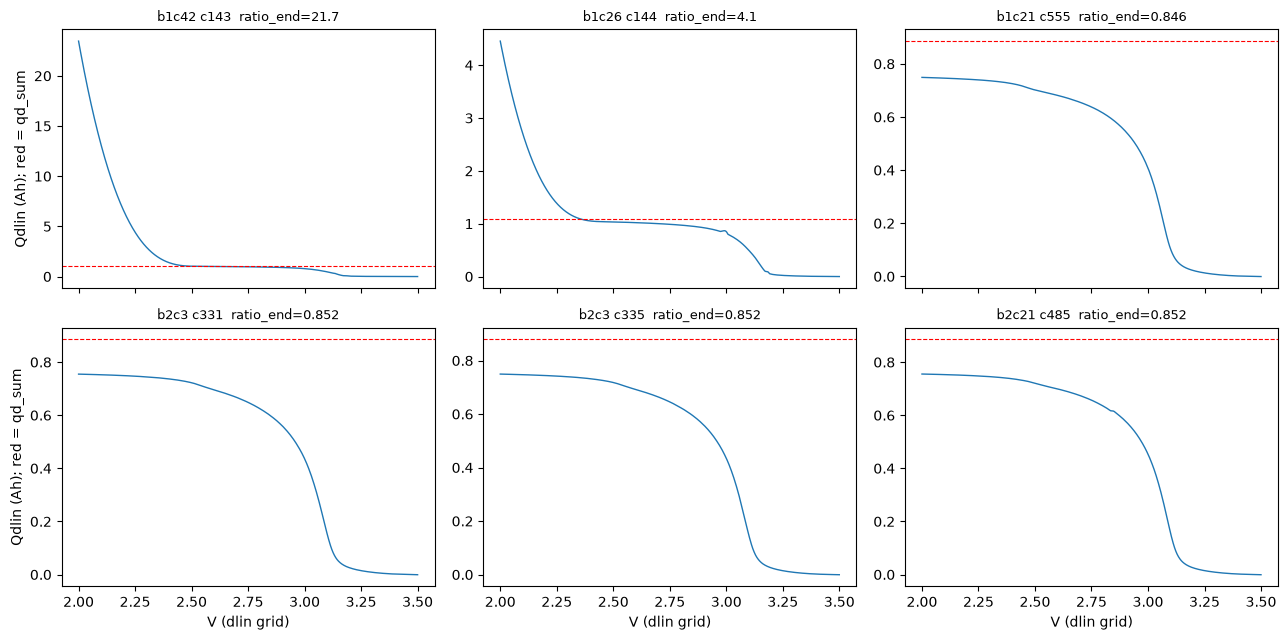

In [6]:
# Scored rows with a bad tail; cell / cycle ranges and overlaps
def tail_flag(lo, hi, ms):
    s = ~((D["ratio_end"] >= lo) & (D["ratio_end"] <= hi) & (D["max_step"] <= ms))
    s[PH] = False   # placeholder rows: not applicable, already removed by qdlin_ok
    return s
susp0 = tail_flag(TAIL_LO, TAIL_HI, MAX_STEP_AH)
bad_s = sc & susp0
def ranges(cs):
    cs = np.sort(np.unique(cs)); out = []; s = p = None
    for c in cs:
        if s is None: s = p = c
        elif c == p + 1: p = c
        else: out.append(f"{s}-{p}" if s != p else f"{s}"); s = p = c
    if s is not None: out.append(f"{s}-{p}" if s != p else f"{s}")
    return ",".join(out)
tab = pd.DataFrame({"cell": cell_s[bad_s], "batch": batch[bad_s], "cyc": cycn[bad_s]}).groupby("cell").agg(
    batch=("batch", "first"), n=("cyc", "size"), cycles=("cyc", lambda s: ranges(s.to_numpy())))
tab["cycles"] = tab["cycles"].str.slice(0, 110)
print(f"scored rows with ratio_end outside [{TAIL_LO},{TAIL_HI}] or max_step > {MAX_STEP_AH}: {int(bad_s.sum())} rows in {len(tab)} cells")
print(tab.sort_values("n", ascending=False).to_string())
b2ev = (batch == 2) & (cycn >= 246) & (cycn <= 258)
ov = {"flag_qd_mismatch": FL["flag_qd_mismatch"], "flag_diag_suspect": FL["flag_diag_suspect"],
      "label_suspect": F["label_suspect"], "b2 cycle 246-258 event": b2ev}
ovt = {k: int((bad_s & v).sum()) for k, v in ov.items()}
anyov = np.zeros(len(lab), bool)
for v in ov.values(): anyov |= v
ovt["none of the four"] = int((bad_s & ~anyov).sum())
print("overlap of bad-tail scored rows:", ovt)
REP["tail"] = [f"ratio_end (non-placeholder, ex flag_qdlin_bad) {rmin:.3g}..{rmax:.3g}; scored rows with ratio_end in [<0.5 | 0.5-0.8 | 0.8-0.85 | 0.85-1.02 | 1.02-1.1 | >1.1]: " + " | ".join(str(int(v)) for v in hist.values),
               f"scored bad-tail rows {int(bad_s.sum())} in {len(tab)} cells; overlap {ovt}"]

# six worst curves
dev_ = np.abs(np.log(np.clip(np.nan_to_num(D["ratio_end"], nan=1e-6), 1e-6, None)))
dev_[~sc] = -1
worst = np.argsort(dev_)[::-1][:6]
fig, axs = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True)
for ax, r in zip(axs.ravel(), worst):
    y = np.asarray(Q[ridx[r]], dtype=np.float64)
    ax.plot(VGRID, y, lw=1); ax.axhline(qd[r], color="r", ls="--", lw=0.8)
    ax.set_title(f"{cell_s[r]} c{cycn[r]}  ratio_end={D['ratio_end'][r]:.3g}", fontsize=9); ax.invert_xaxis()
for ax in axs[1]: ax.set_xlabel("V (dlin grid)")
for ax in axs[:, 0]: ax.set_ylabel("Qdlin (Ah); red = qd_sum")
fig.tight_layout(); fig.savefig(guard_write(FIG/"worst_tail_curves.png"), dpi=130); plt.show()

In [7]:
# Reproduce the Phase 3 canary numbers on scored development rows (Phase 3 mask, repeat-0 folds)
m = sc_dev
def win_w(o, c):
    return qc(c) - qc(o)
repro = {}
for (o, c) in [(3.2, 2.4), (3.5, 2.4), (3.5, 2.0)]:
    w = win_w(o, c)
    r2, mae, _ = canary(w[m], soh[m], ccode[m])
    repro[(o, c)] = (r2, mae); print(f"canary {o}->{c} V (Phase 3 mask): R2={r2:.3f}, MAE={mae:.2f} pp")
w20 = win_w(3.5, 2.0)
corr = {int(b): np.corrcoef(w20[m & (batch == b)], qd[m & (batch == b)])[0, 1] for b in sorted(np.unique(batch[m]))}
print("corr(w(2.0 V), qd_sum) per batch:", {k: round(v, 3) for k, v in corr.items()})
expect("reproduce R2 0.926 at 3.2->2.4", abs(repro[(3.2, 2.4)][0] - 0.926) < 0.02, f"{repro[(3.2, 2.4)][0]:.3f}")
expect("reproduce R2 -0.93 at 3.5->2.0", abs(repro[(3.5, 2.0)][0] + 0.93) < 0.1, f"{repro[(3.5, 2.0)][0]:.3f}")
expect("reproduce corr 0.47 (batch 1)", abs(corr.get(1, np.nan) - 0.47) < 0.03, f"{corr.get(1, np.nan):.3f}")
expect("reproduce corr 0.96 (batch 2)", abs(corr.get(2, np.nan) - 0.96) < 0.03, f"{corr.get(2, np.nan):.3f}")
REP["tail"].append(f"Phase 3 canary repro: 3.2->2.4 R2 {repro[(3.2, 2.4)][0]:.3f}; 3.5->2.4 R2 {repro[(3.5, 2.4)][0]:.3f}; 3.5->2.0 R2 {repro[(3.5, 2.0)][0]:.3f}; corr(w2.0,qd_sum) by batch {({k: round(v, 2) for k, v in corr.items()})}")

canary 3.2->2.4 V (Phase 3 mask): R2=0.926, MAE=0.01 pp
canary 3.5->2.4 V (Phase 3 mask): R2=0.917, MAE=0.01 pp
canary 3.5->2.0 V (Phase 3 mask): R2=-0.927, MAE=0.02 pp
corr(w(2.0 V), qd_sum) per batch: {1: np.float64(0.484), 2: np.float64(0.965)}
[PASS] reproduce R2 0.926 at 3.2->2.4: 0.926
[PASS] reproduce R2 -0.93 at 3.5->2.0: -0.927
[PASS] reproduce corr 0.47 (batch 1): 0.484
[PASS] reproduce corr 0.96 (batch 2): 0.965


## 3. Offline mask v2 and per-window causal validity

In [8]:
susp = susp0
qdlin_ok = F["qdlin_ok"]
qdlin_ok2 = qdlin_ok & ~susp
scored2 = F["scored"] & qdlin_ok2
check("scored2 is a subset of scored", not (scored2 & ~F["scored"]).any(), f"scored {int(F['scored'].sum())} -> scored2 {int(scored2.sum())}")

# sensitivity of the bounds (rows removed from Phase 3 scored; full-window canary on development rows)
w_full = win_w(3.5, 2.0)
rows = []
for lo in (0.70, 0.80, 0.85):
    for hi in (1.0, 1.02, 1.10):
        for ms in (0.02, 0.05, 0.10):
            s_ = tail_flag(lo, hi, ms); keep = F["scored"] & F["is_dev"] & ~s_
            r2, mae, _ = canary(w_full[keep], soh[keep], ccode[keep])
            rows.append({"TAIL_LO": lo, "TAIL_HI": hi, "MAX_STEP": ms, "removed_scored": int((F["scored"] & s_).sum()),
                         "removed_dev": int((sc_dev & s_).sum()), "full_R2": round(r2, 4), "MAE_pp": round(mae, 3)})
SENS = pd.DataFrame(rows); print(SENS.to_string(index=False))
REP["sens"] = SENS

# per-batch counts and per-cell removal
bt = pd.DataFrame({"batch": batch, "scored": F["scored"], "scored2": scored2, "dev_scored": sc_dev, "dev_scored2": scored2 & F["is_dev"]}).groupby("batch").sum()
bt["removed"] = bt["scored"] - bt["scored2"]; print(bt.to_string()); REP["batch_counts"] = bt
il = F["in_life"]
cell_tab = pd.DataFrame({"cell": cell_s[il], "rm_total": (~qdlin_ok2)[il], "rm_incremental": (qdlin_ok & susp)[il]}).groupby("cell").mean()
cell_tab["batch"] = [batch[cell_s == c][0] for c in cell_tab.index]
over2 = cell_tab[cell_tab["rm_total"] > 0.02].sort_values("rm_total", ascending=False)
print("cells with > 2% of in-life rows removed by qdlin_ok2 (total, and incremental over qdlin_ok):"); print(over2.round(4).to_string())
expect("b2c40 above 2%", any(str(c).lower().replace("_", "") in ("b2c40",) or str(c).endswith("b2c40") for c in over2.index), list(over2.index)[:10])
hd_cells = set(cell_tab.index[cell_tab["rm_total"] > 0.10])
high_defect = pd.Series(cell_s).isin(hd_cells).to_numpy()
print("high_defect_cell (>10% of in-life rows removed):", sorted(hd_cells))
REP["hd"] = sorted(hd_cells); REP["over2"] = over2

[PASS] scored2 is a subset of scored: scored 100795 -> scored2 100793
 TAIL_LO  TAIL_HI  MAX_STEP  removed_scored  removed_dev  full_R2  MAE_pp
     0.7        1      0.02              48           47   0.9178    0.01
     0.7        1      0.05              17           16   0.9178    0.01
     0.7        1       0.1              17           16   0.9178    0.01
     0.7     1.02      0.02              33           33   0.9176    0.01
     0.7     1.02      0.05               2            2   0.9176    0.01
     0.7     1.02       0.1               2            2   0.9176    0.01
     0.7      1.1      0.02              33           33   0.9176    0.01
     0.7      1.1      0.05               2            2   0.9176    0.01
     0.7      1.1       0.1               2            2   0.9176    0.01
     0.8        1      0.02              48           47   0.9178    0.01
     0.8        1      0.05              17           16   0.9178    0.01
     0.8        1       0.1              1

In [9]:
# Causal per-window validity: append ONE function to src/soh_common.py (existing bytes untouched)
WV_SRC = """def window_valid(qdlin_row, i_open, i_close, max_step_ah=0.05):
    # Serving-time validity of a Qdlin slice [i_open, i_close]; uses no label.
    import numpy as _np
    q = _np.asarray(qdlin_row, dtype=_np.float64)
    if q.ndim != 1 or not (0 <= i_open < i_close < q.size):
        return False
    if (not _np.isfinite(q[0])) or abs(q[0]) > 0.01:
        return False
    s = q[i_open:i_close + 1]
    if not _np.all(_np.isfinite(s)):
        return False
    d = _np.diff(s)
    if d.size and (d.min() < -5e-3 or d.max() > max_step_ah):
        return False
    if s.min() < -0.01 or s.max() > 1.3:
        return False
    return True
"""
if "def window_valid" in SC_TEXT0:
    print("window_valid already present in soh_common.py; not appending again")
else:
    new = SC_BYTES0 + (b"" if SC_BYTES0.endswith(b"\n") else b"\n") + b"\n" + WV_SRC.encode("utf-8")
    guard_write(SC).write_bytes(new)
    print("appended window_valid to", SC)
sc_bytes1 = SC.read_bytes()
if "def window_valid" not in SC_TEXT0:
    check("soh_common.py: original bytes are an exact prefix", sc_bytes1.startswith(SC_BYTES0))
sys.path.insert(0, str(SRC)); importlib.invalidate_caches(); sys.modules.pop("soh_common", None)
soh_common = importlib.import_module("soh_common")
window_valid = soh_common.window_valid
print("imported from:", soh_common.__file__)

# tests: one valid row and three corrupted rows (plus a causality illustration)
ok_pos = np.flatnonzero(scored2 & F["is_dev"])[0]
row = np.asarray(Q[ridx[ok_pos]], dtype=np.float64)
c1 = row.copy(); c1[500] = np.nan
c2 = row.copy(); c2[700:] += 0.3
c3 = row + 0.05
t = [window_valid(row, 0, 999), window_valid(c1, 0, 999), window_valid(c2, 0, 999), window_valid(c3, 0, 999)]
check("window_valid: valid row True, three corrupted rows False", t == [True, False, False, False], t)
check("window_valid is causal (tail jump after 3.1 V does not invalidate a window closing at 3.1 V)", window_valid(c2, 0, I31) is True and window_valid(c2, 0, 999) is False)

# vectorised per-window validity from the cached cumulative counts
def wv_vec(o, c):
    io, ic = vidx(o), vidx(c)
    bv = CV[:, VCOLS.index(ic)].astype(np.int32); bs = CS[:, SCOLS.index(ic - 1)].astype(np.int32)
    if io > 0:
        bv = bv - CV[:, VCOLS.index(io - 1)]; bs = bs - CS[:, SCOLS.index(io - 1)]
    return OK0 & (bv == 0) & (bs == 0)
WV = {w: wv_vec(*w) for w in WIN}
samp = np.concatenate([rng.choice(np.flatnonzero(sc_dev), 200, replace=False), rng.choice(np.flatnonzero(susp & F["scored"]), min(200, int((susp & F["scored"]).sum())), replace=False)])
mism = 0; tot = 0
for p in samp:
    r_ = np.asarray(Q[ridx[p]], dtype=np.float64)
    for w in [(3.5, 2.0), (3.5, 3.1), (3.5, 2.5), (3.3, 3.0), (3.0, 2.8), (3.2, 2.4)]:
        mism += int(window_valid(r_, vidx(w[0]), vidx(w[1])) != WV[w][p]); tot += 1
check("vectorised window validity equals window_valid()", mism == 0, f"{mism} mismatches in {tot} spot checks")

# catch rate of the causal validity on rows removed by qdlin_tail_suspect
rem = F["scored"] & susp
catch = {}
for name, w in {"full 3.5->2.0": (3.5, 2.0), "3.5->3.1": (3.5, 3.1), "3.5->2.5": (3.5, 2.5)}.items():
    catch[name] = (float((~WV[w][rem]).mean()), int((~WV[w][rem]).sum()))
    print(f"catch rate {name}: {catch[name][0]:.3f} ({catch[name][1]} of {int(rem.sum())} removed scored rows)")
REP["catch"] = catch; REP["n_rem"] = int(rem.sum())
for nm, msk in {"ratio_end out of bounds only": rem & (D["max_step"] <= MAX_STEP_AH), "max_step only": rem & (D["max_step"] > MAX_STEP_AH)}.items():
    if msk.any(): print(f"  {nm}: n={int(msk.sum())}, full-window catch {float((~WV[(3.5, 2.0)][msk]).mean()):.3f}")

appended window_valid to c:\workstation\3RD YEAR\Battery-Health-Estimation\src\soh_common.py
[PASS] soh_common.py: original bytes are an exact prefix: 
imported from: c:\workstation\3RD YEAR\Battery-Health-Estimation\src\soh_common.py
[PASS] window_valid: valid row True, three corrupted rows False: [True, False, False, False]
[PASS] window_valid is causal (tail jump after 3.1 V does not invalidate a window closing at 3.1 V): 
[PASS] vectorised window validity equals window_valid(): 0 mismatches in 1212 spot checks
catch rate full 3.5->2.0: 1.000 (2 of 2 removed scored rows)
catch rate 3.5->3.1: 0.000 (0 of 2 removed scored rows)
catch rate 3.5->2.5: 0.000 (0 of 2 removed scored rows)
  ratio_end out of bounds only: n=1, full-window catch 1.000
  max_step only: n=1, full-window catch 1.000


In [10]:
# Write labels_table_v2.parquet (labels_table plus the new columns; labels_table.parquet is not touched)
v2 = lab.copy()
v2["ratio_end"] = D["ratio_end"].astype(np.float32); v2["max_step"] = D["max_step"].astype(np.float32)
v2["qdlin_tail_suspect"] = susp; v2["qdlin_ok2"] = qdlin_ok2; v2["scored2"] = scored2; v2["high_defect_cell"] = high_defect
p_v2 = guard_write(PROC/"labels_table_v2.parquet"); v2.to_parquet(p_v2, index=False)
chk = pd.read_parquet(p_v2)
check("labels_table_v2 keeps every original column unchanged", chk[list(lab.columns)].equals(lab) and len(chk) == len(lab), f"{chk.shape}")

[PASS] labels_table_v2 keeps every original column unchanged: (104971, 26)


## 4. Window regrid and audit (scored2 development rows, Protocol D repeat 0)

In [11]:
# Working arrays on Phase 3 scored development rows; A is the scored2 subset
W = np.flatnonzero(sc_dev)
Qw, yw, cw, qdw, q0w, TKw = Qc[W], soh[W], ccode[W], qd[W], q0[W], TKl[W]
inA = scored2[W]; allT = np.ones(len(W), bool)
def ci(v):
    return COLS.index(vidx(v))
# gate: full-window canary on A must reach 0.90
wf = Qw[:, ci(2.0)].astype(float) - Qw[:, ci(3.5)]
r2f, maef, pf = canary(wf[inA], yw[inA], cw[inA])
print(f"full-window 3.5->2.0, rows A: R2={r2f:.4f}, MAE={maef:.2f} pp")
STOP_AUDIT = not (r2f >= 0.90)
check("full-window R2(A) >= 0.90", not STOP_AUDIT, f"{r2f:.4f}")
if STOP_AUDIT:
    idxA = np.flatnonzero(inA); res = np.abs(yw[idxA] - pf); o = np.argsort(np.nan_to_num(res, nan=-1))[::-1][:20]
    top = pd.DataFrame({"cell": CELLS_U[cw[idxA][o]], "cycle": cycn[W][idxA][o], "w": wf[idxA][o], "qd_sum": qdw[idxA][o],
                        "soh_nom": yw[idxA][o], "pred": pf[o], "abs_resid": res[o]})
    print("STOP: printing the 20 largest held-out residual rows instead of the grid"); print(top.to_string(index=False))

full-window 3.5->2.0, rows A: R2=0.9176, MAE=0.01 pp
[PASS] full-window R2(A) >= 0.90: 0.9176


In [12]:
AUDIT = None
if not STOP_AUDIT:
    idxA = np.flatnonzero(inA); ordA = idxA[np.argsort(cw[idxA], kind="stable")]
    sc_codes = cw[ordA]; cuts = np.flatnonzero(np.diff(sc_codes)) + 1
    seg_codes = sc_codes[np.r_[0, cuts]]; seg_batch = cellbatch[seg_codes]
    t20 = np.nanmedian(TKw[inA, 15])
    recs = []
    for (o, c) in tqdm(WIN, desc="window audit"):
        io, ic = vidx(o), vidx(c)
        w = Qw[:, ci(c)].astype(float) - Qw[:, ci(o)]
        valid = WV[(o, c)][W]
        L = Qw[ordA, ci(c)].astype(float)/qdw[ordA]; segs = np.split(L, cuts)
        cm = np.array([s.mean() for s in segs]); cmed = np.array([np.median(s) for s in segs])
        el = float(np.median(Qw[inA, ci(c)]*MIN_PER_AH))
        isknot = abs(c*10 - round(c*10)) < 1e-6
        if isknot:
            ek = float(np.nanmedian(TKw[inA, int(round((3.5 - c)/0.1))])); saved = t20 - ek; kd = ek - el
        else:
            ek = np.nan; saved = t20 - el; kd = np.nan
        width = ic - io + 1
        rec = {"open": o, "close": c, "i_open": io, "i_close": ic, "width_pts": width, "stride32": round((width - 1)/31, 2),
               "n_A": int(inA.sum()), "L_mean": cm.mean(), "L_median": np.median(cmed),
               "L_mean_b1": cm[seg_batch == 1].mean() if (seg_batch == 1).any() else np.nan,
               "L_mean_b2": cm[seg_batch == 2].mean() if (seg_batch == 2).any() else np.nan,
               "elapsed_min": el, "elapsed_knot": ek, "knot_diff": kd, "minutes_saved": saved}
        for tag, msk in (("A", inA), ("B", valid), ("C", allT)):
            r2, mae, _ = canary(w[msk], yw[msk], cw[msk])
            r2q, maeq, _ = canary(w[msk], yw[msk], cw[msk], extra=q0w[msk])
            rec.update({f"r2_{tag}": r2, f"mae_{tag}_pp": mae, f"r2q0_{tag}": r2q, f"maeq0_{tag}_pp": maeq, f"n_{tag}": int(msk.sum())})
        rec["oracle"] = bool(rec["r2_A"] > CANARY_R2); rec["late"] = bool(rec["L_mean"] > LATE_WINDOW_L)
        rec["cls"] = "oracle+late" if rec["oracle"] and rec["late"] else "oracle" if rec["oracle"] else "late" if rec["late"] else "open"
        recs.append(rec)
    AUDIT = pd.DataFrame(recs)
    for c_ in AUDIT.columns:
        if AUDIT[c_].dtype == float: AUDIT[c_] = AUDIT[c_].round(5)
    AUDIT.to_csv(guard_write(OUT/"window_audit_v2.csv"), index=False)
    print("saved window_audit_v2.csv", AUDIT.shape)
    ref_row = AUDIT[(AUDIT["open"] == 3.5) & (AUDIT["close"] == 2.0)].iloc[0]
    print(f"full window: R2 A/B/C = {ref_row['r2_A']:.3f} / {ref_row['r2_B']:.3f} / {ref_row['r2_C']:.3f}")
    kn = AUDIT.dropna(subset=["knot_diff"])
    print("elapsed_min (Qdlin*15) minus t_knots at knot closes: median %.3f, max abs %.3f min" % (kn["knot_diff"].median(), kn["knot_diff"].abs().max()))
    for thr in (0.90, 0.95):
        print(f"\nearliest closing window with R2(A) >= {thr}, per open voltage:")
        e = []
        for o in OPENS:
            s = AUDIT[(AUDIT["open"] == o) & (AUDIT["r2_A"] >= thr)]
            e.append(s.nsmallest(1, "elapsed_min").iloc[0][["open", "close", "elapsed_min", "minutes_saved", "L_mean", "r2_A", "mae_A_pp"]] if len(s) else pd.Series({"open": o, "close": np.nan}))
        print(pd.DataFrame(e).to_string(index=False))
    print("\nclassification counts:"); print(AUDIT["cls"].value_counts().to_string())

window audit: 100%|██████████| 95/95 [00:25<00:00,  3.69it/s]

saved window_audit_v2.csv (95, 32)
full window: R2 A/B/C = 0.918 / 0.918 / -0.927
elapsed_min (Qdlin*15) minus t_knots at knot closes: median -1.313, max abs 1.368 min

earliest closing window with R2(A) >= 0.9, per open voltage:
 open  close  elapsed_min  minutes_saved  L_mean    r2_A  mae_A_pp
  3.5    2.4       14.886        0.33005 0.93176 0.91726   0.01045
  3.4    2.4       14.886        0.33005 0.93176 0.91772   0.01044
  3.3    2.4       14.886        0.33005 0.93176 0.91896   0.01039
  3.2    2.4       14.886        0.33005 0.93176 0.92678    0.0099
  3.1    NaN          NaN            NaN     NaN     NaN       NaN
    3    NaN          NaN            NaN     NaN     NaN       NaN

earliest closing window with R2(A) >= 0.95, per open voltage:
 open  close
  3.5    NaN
  3.4    NaN
  3.3    NaN
  3.2    NaN
  3.1    NaN
    3    NaN

classification counts:
cls
late    78
open    17


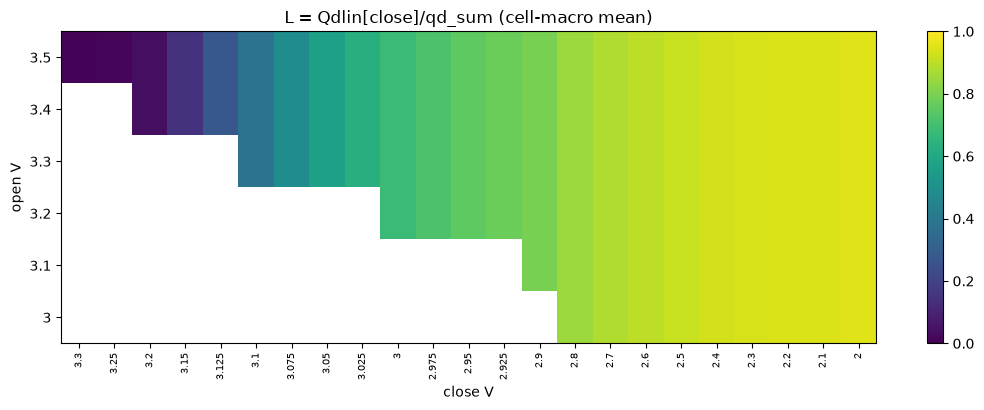

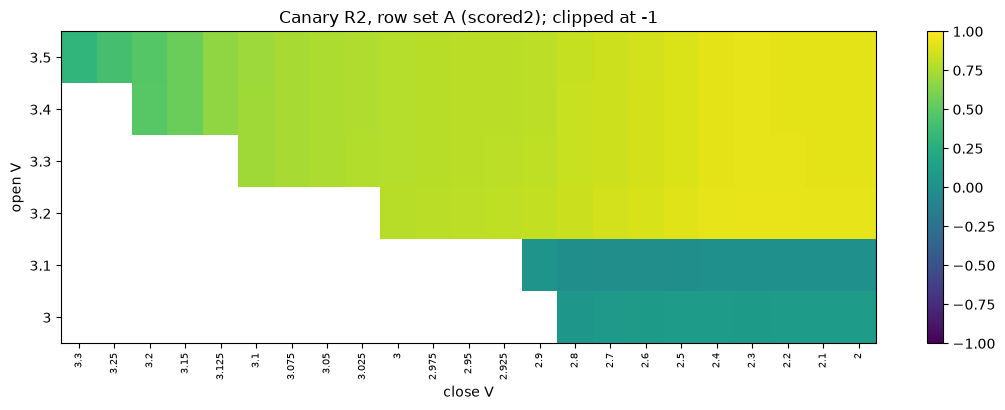

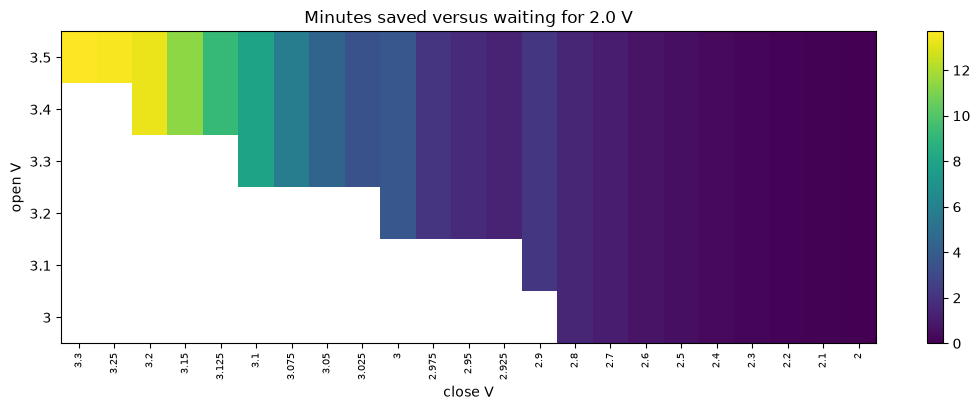

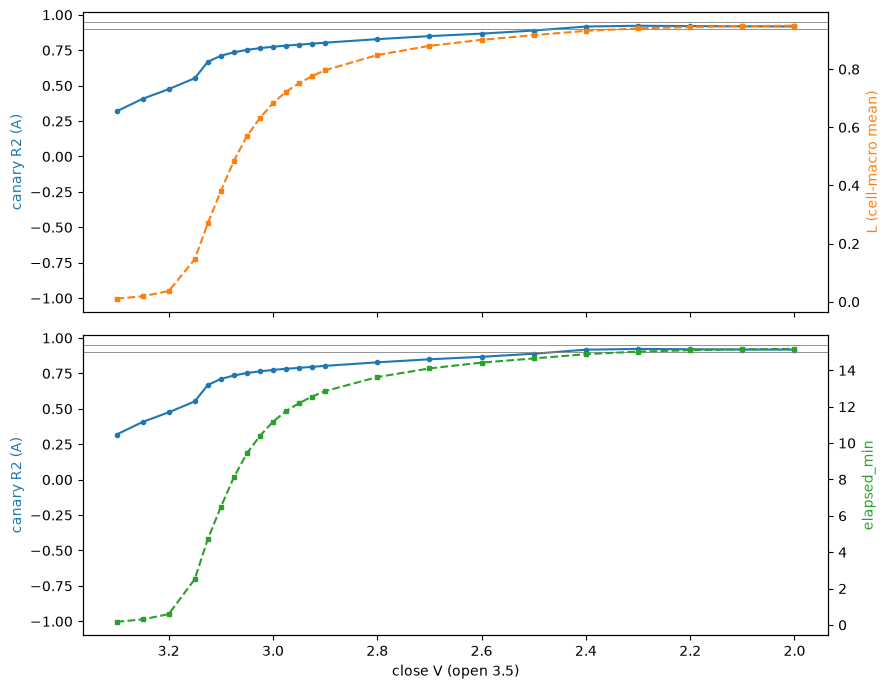

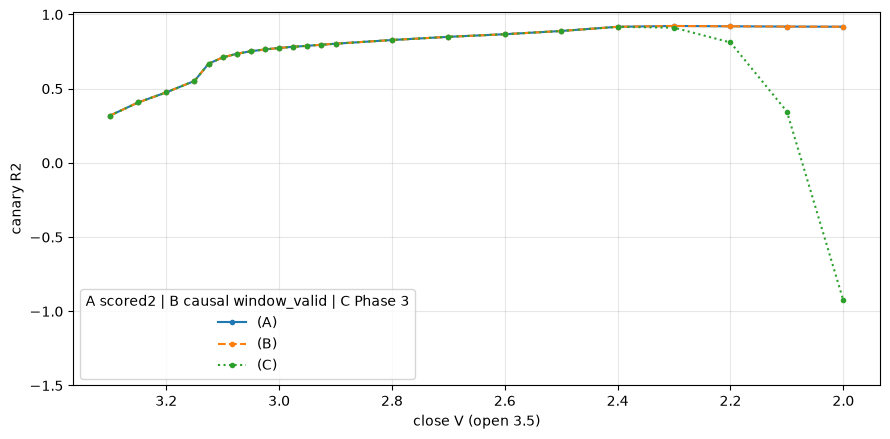

In [13]:
# Figures
if AUDIT is not None:
    def heat(col, title, fn, vmin=None, vmax=None):
        piv = AUDIT.pivot(index="open", columns="close", values=col).sort_index(ascending=False)
        piv = piv[sorted(piv.columns, reverse=True)]
        fig, ax = plt.subplots(figsize=(11, 4.2))
        im = ax.imshow(piv.values.astype(float), aspect="auto", vmin=vmin, vmax=vmax, cmap="viridis")
        ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels([f"{c:g}" for c in piv.columns], rotation=90, fontsize=7)
        ax.set_yticks(range(piv.shape[0])); ax.set_yticklabels([f"{o:g}" for o in piv.index])
        ax.set_xlabel("close V"); ax.set_ylabel("open V"); ax.set_title(title); fig.colorbar(im, ax=ax)
        fig.tight_layout(); fig.savefig(guard_write(FIG/fn), dpi=130); plt.show()
    heat("L_mean", "L = Qdlin[close]/qd_sum (cell-macro mean)", "heatmap_L.png", 0, 1)
    heat("r2_A", "Canary R2, row set A (scored2); clipped at -1", "heatmap_r2_A.png", -1, 1)
    heat("minutes_saved", "Minutes saved versus waiting for 2.0 V", "heatmap_minutes_saved.png")
    s = AUDIT[AUDIT["open"] == 3.5].sort_values("close", ascending=False)
    fig, axs = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
    for ax, col, lab_, colr in ((axs[0], "L_mean", "L (cell-macro mean)", "C1"), (axs[1], "elapsed_min", "elapsed_min", "C2")):
        ax.plot(s["close"], s["r2_A"], "o-", color="C0", ms=3); ax.set_ylabel("canary R2 (A)", color="C0"); ax.set_ylim(-1.1, 1.02)
        a2 = ax.twinx(); a2.plot(s["close"], s[col], "s--", color=colr, ms=3); a2.set_ylabel(lab_, color=colr)
        ax.axhline(0.90, color="gray", lw=0.6); ax.axhline(0.95, color="gray", lw=0.6)
    axs[1].set_xlabel("close V (open 3.5)"); axs[1].invert_xaxis(); fig.tight_layout(); fig.savefig(guard_write(FIG/"r2_L_elapsed_open35.png"), dpi=130); plt.show()
    fig, ax = plt.subplots(figsize=(9, 4.5))
    for tag, st_ in (("A", "-"), ("B", "--"), ("C", ":")):
        ax.plot(s["close"], s[f"r2_{tag}"], st_, marker="o", ms=3, label=f"({tag})")
    ax.set_ylim(-1.5, 1.02); ax.invert_xaxis(); ax.set_xlabel("close V (open 3.5)"); ax.set_ylabel("canary R2")
    ax.legend(title="A scored2 | B causal window_valid | C Phase 3"); ax.grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(guard_write(FIG/"r2_ABC_open35.png"), dpi=130); plt.show()

## 5. Exploratory (no thresholds)

In [14]:
irc = [c for c in cycf.columns if c.lower() in ("ir", "internal_resistance", "ir_ohm")]
if not irc:
    ERRORS.append("cycles_table: no ir column found; ir correlations skipped"); check("ir column present", False, list(cycf.columns)[:30])
irv = cycf[irc[0]].to_numpy(float) if irc else np.full(len(lab), np.nan)
q31 = qc(3.1); mm = scored2 & F["is_dev"]; exp_rows = []
for b in sorted(np.unique(batch[mm])):
    mb = mm & (batch == b); mi = mb & (irv > 0) & np.isfinite(irv)
    r1 = spearmanr(q31[mb], soh[mb])[0]; r2_ = spearmanr(q31[mi], irv[mi])[0] if mi.sum() > 2 else np.nan
    exp_rows.append({"batch": b, "n": int(mb.sum()), "spearman(Q@3.1V, soh_nom)": round(r1, 3), "n_ir": int(mi.sum()), "spearman(Q@3.1V, ir)": round(r2_, 3)})
EXPL = pd.DataFrame(exp_rows); print(EXPL.to_string(index=False))

 batch     n  spearman(Q@3.1V, soh_nom)  n_ir  spearman(Q@3.1V, ir)
     1 41089                      0.805 41084                -0.656
     2 19248                      0.934 19248                -0.632


## 6. Checks and report

In [15]:
check("scored2 is a subset of scored", not (scored2 & ~F["scored"]).any())
H1 = verify_hashes()
check("split hashes unchanged at end", H1 == H0 and all(ok for _, ok in H1), f"{len(H1)} files")
check("labels_table.parquet unchanged", sha256(PROC/"labels_table.parquet") == LABELS_SHA0)
n_est = sum(isinstance(v, BaseEstimator) for v in globals().values())
bad_mods = [m for m in ("torch", "tensorflow", "xgboost", "lightgbm") if m in sys.modules]
check("no model objects created", n_est == 0 and not bad_mods, f"estimators {n_est}, ML modules {bad_mods}")
SC_AST1 = ast_map(SC.read_text(encoding="utf-8"))
check("soh_common.py existing functions unchanged (AST vs start of notebook)", SC_AST1 == SC_AST0, f"{len(SC_AST0)} nodes")
p3copy = P3/"soh_common.py"
if p3copy.exists():
    expect("soh_common.py matches the outputs/phase3 copy (AST)", ast_map(p3copy.read_text(encoding="utf-8")) == SC_AST1)
check("window_valid is defined exactly once in soh_common.py", SC.read_text(encoding="utf-8").count("def window_valid") == 1)
check("no write inside splits", True)
if AUDIT is not None:
    kn = AUDIT.dropna(subset=["knot_diff"])
    expect("elapsed_min agrees with t_knots at knot closes (median |diff| < 0.3 min)", kn["knot_diff"].abs().median() < 0.3, f"{kn['knot_diff'].abs().median():.3f}")
print(pd.DataFrame(CHECKS).groupby("status").size().to_dict())

[PASS] scored2 is a subset of scored: 
[PASS] split hashes unchanged at end: 5 files
[PASS] labels_table.parquet unchanged: 
[PASS] no model objects created: estimators 0, ML modules []
[PASS] soh_common.py existing functions unchanged (AST vs start of notebook): 26 nodes
[PASS] window_valid is defined exactly once in soh_common.py: 
[PASS] no write inside splits: 
[WARN] elapsed_min agrees with t_knots at knot closes (median |diff| < 0.3 min): 1.313
{'PASS': 31, 'WARN': 5}


In [16]:
# Assemble the report
def fmt_df(df, **kw):
    return df.to_string(**kw)
L = []
runtime = time.time() - T0
L.append("PHASE 3B REPORT"); L.append(f"runtime: {runtime:.0f} s | seed {SEED} | TAIL_LO {TAIL_LO} TAIL_HI {TAIL_HI} MAX_STEP_AH {MAX_STEP_AH}")
L.append(""); L.append("TAIL DIAGNOSIS"); L += ["  " + s for s in REP["tail"]]
L.append(""); L.append("MASK V2 (rows per batch)"); L.append(fmt_df(REP["batch_counts"]))
L.append(f"  high-defect cells (>10% of in-life rows removed): {REP['hd']}")
L.append("  cells > 2% removed: " + (", ".join(f"{i} {v:.1%}" for i, v in REP["over2"]["rm_total"].items()) or "none"))
L.append(""); L.append("BOUND SENSITIVITY (rows removed from scored; full-window canary R2)"); L.append(fmt_df(REP["sens"], index=False))
L.append(""); L.append(f"CATCH RATE of causal window_valid on the {REP['n_rem']} scored rows removed by qdlin_tail_suspect")
for k, (fr, n) in REP["catch"].items(): L.append(f"  {k}: {fr:.3f} ({n} rows)")
L.append(""); L.append("WINDOW AUDIT")
if AUDIT is None:
    L.append(f"  STOPPED: full-window R2(A) = {r2f:.3f} < 0.90 (see notebook output for the 20 largest residual rows)")
    REP_R2 = {}
else:
    rr = AUDIT[(AUDIT["open"] == 3.5) & (AUDIT["close"] == 2.0)].iloc[0]; r24 = AUDIT[(AUDIT["open"] == 3.5) & (AUDIT["close"] == 2.4)].iloc[0]
    L.append(f"  full 3.5->2.0 R2: before (C, Phase 3 mask) {rr['r2_C']:.3f} | causal-valid only (B) {rr['r2_B']:.3f} | after (A, scored2) {rr['r2_A']:.3f}")
    L.append(f"  3.5->2.4 R2: C {r24['r2_C']:.3f} | B {r24['r2_B']:.3f} | A {r24['r2_A']:.3f}")
    ok9 = AUDIT[AUDIT["r2_A"] >= 0.90].nsmallest(10, "elapsed_min")[["open", "close", "elapsed_min", "minutes_saved", "L_mean", "r2_A", "mae_A_pp", "r2q0_A", "cls"]]
    L.append("  10 windows with lowest elapsed_min and R2(A) >= 0.90:"); L.append(fmt_df(ok9.round(3), index=False) if len(ok9) else "  none")
    cc = AUDIT["cls"].value_counts()
    L.append(f"  classification of {len(AUDIT)} windows: oracle {int(AUDIT['oracle'].sum())} | late {int(AUDIT['late'].sum())} | open (neither) {int((AUDIT['cls'] == 'open').sum())} | {cc.to_dict()}")
L.append(""); L.append("EXPLORATORY (Spearman, scored2 dev)"); L.append(fmt_df(EXPL, index=False))
L.append(""); L.append("CHECKS")
for s_ in ("PASS", "WARN", "FAIL"):
    items = [c for c in CHECKS if c["status"] == s_]
    L.append(f"  {s_} ({len(items)})")
    for c in items: L.append(f"    - {c['name']}: {c['detail'][:140]}")
L.append(""); L.append("ERRORS"); L += ([f"  {e}" for e in ERRORS] or ["  none"])
arts = [OUT/"window_audit_v2.csv", PROC/"labels_table_v2.parquet", SC] + sorted(FIG.glob("*.png"))
L.append(""); L.append("ARTIFACTS")
for p in arts:
    if Path(p).exists(): L.append(f"  {Path(p).relative_to(ROOT)}  {Path(p).stat().st_size/1024:.1f} KB")
L.append("  outputs/phase3b/phase3b_report.txt, outputs/phase3b/verification_report.json (this report, sizes not listed)")
text = "\n".join(L)
guard_write(OUT/"phase3b_report.txt").write_text(text, encoding="utf-8")
ver = {"runtime_s": round(runtime, 1), "checks": CHECKS, "errors": ERRORS,
       "counts": {"scored": int(F["scored"].sum()), "scored2": int(scored2.sum()), "dev_scored": int(sc_dev.sum()), "dev_scored2": int((scored2 & F["is_dev"]).sum())},
       "full_window_R2_A": None if AUDIT is None else float(rr["r2_A"]), "stopped_audit": bool(STOP_AUDIT),
       "artifacts": {str(Path(p).relative_to(ROOT)): Path(p).stat().st_size for p in arts if Path(p).exists()}}
guard_write(OUT/"verification_report.json").write_text(json.dumps(ver, indent=2, default=str), encoding="utf-8")

5311

In [17]:
print((OUT/"phase3b_report.txt").read_text(encoding="utf-8"))

PHASE 3B REPORT
runtime: 42 s | seed 42 | TAIL_LO 0.8 TAIL_HI 1.02 MAX_STEP_AH 0.05

TAIL DIAGNOSIS
  ratio_end (non-placeholder, ex flag_qdlin_bad) 7.73e-05..21.7; scored rows with ratio_end in [<0.5 | 0.5-0.8 | 0.8-0.85 | 0.85-1.02 | 1.02-1.1 | >1.1]: 0 | 0 | 1 | 100792 | 0 | 2
  scored bad-tail rows 2 in 2 cells; overlap {'flag_qd_mismatch': 0, 'flag_diag_suspect': 0, 'label_suspect': 0, 'b2 cycle 246-258 event': 0, 'none of the four': 2}
  Phase 3 canary repro: 3.2->2.4 R2 0.926; 3.5->2.4 R2 0.917; 3.5->2.0 R2 -0.927; corr(w2.0,qd_sum) by batch {1: np.float64(0.48), 2: np.float64(0.96)}

MASK V2 (rows per batch)
       scored  scored2  dev_scored  dev_scored2  removed
batch                                                   
1       41091    41089       41091        41089        2
2       19248    19248       19248        19248        0
3       40456    40456           0            0        0
  high-defect cells (>10% of in-life rows removed): ['b2c40']
  cells > 2% removed: b2c40 4